In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving traffic_annotation_results (1).csv to traffic_annotation_results (1).csv


In [3]:
import zipfile
import os

print("Uploaded files:", list(uploaded.keys()))

zip_path = next(iter(uploaded.keys()))

if zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/dataset')

    print("Dataset extracted successfully!")
else:
    print("Error: The uploaded file is not a ZIP file.")

Uploaded files: ['traffic_annotation_results (1).csv']
Error: The uploaded file is not a ZIP file.


In [4]:
dataset_path = "/content/dataset"

classes = [
    "Crop_Stress",
    "Diseased",
    "Healthy",
    "Pest_Affected",
    "Weed_Affected"
]

print("Dataset Path:", dataset_path)
print("Classes:", classes)

Dataset Path: /content/dataset
Classes: ['Crop_Stress', 'Diseased', 'Healthy', 'Pest_Affected', 'Weed_Affected']


In [5]:
for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    if os.path.exists(class_path):
        print(class_name, "folder exists")
    else:
        print(class_name, "folder not found")

Crop_Stress folder not found
Diseased folder not found
Healthy folder not found
Pest_Affected folder not found
Weed_Affected folder not found


In [6]:
class_counts = {}

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    if os.path.exists(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        class_counts[class_name] = len(images)
    else:
        class_counts[class_name] = 0

print("Class Distribution:")
print(class_counts)

Class Distribution:
{'Crop_Stress': 0, 'Diseased': 0, 'Healthy': 0, 'Pest_Affected': 0, 'Weed_Affected': 0}


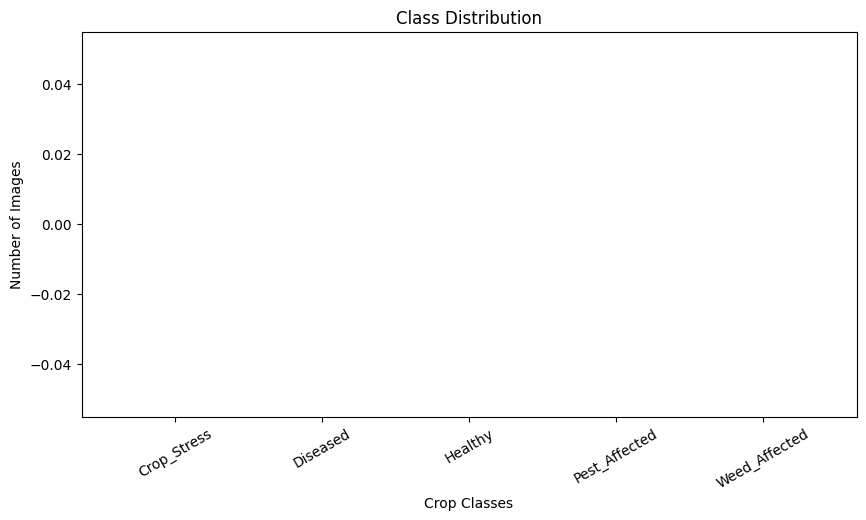

In [7]:
plt.figure(figsize=(10, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Class Distribution")
plt.xlabel("Crop Classes")
plt.ylabel("Number of Images")

plt.xticks(rotation=30)
plt.show()

In [8]:
image_data = []
corrupted_images = []

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    if not os.path.exists(class_path):
        continue

    for file in os.listdir(class_path):

        if not file.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue

        image_path = os.path.join(class_path, file)

        img = cv2.imread(image_path)

        if img is None:
            corrupted_images.append(image_path)
            continue

        height, width, channels = img.shape

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        brightness = np.mean(gray)

        sharpness = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        image_data.append([
            file,
            class_name,
            width,
            height,
            brightness,
            sharpness
        ])

df = pd.DataFrame(
    image_data,
    columns=[
        "Image",
        "Class",
        "Width",
        "Height",
        "Brightness",
        "Sharpness"
    ]
)

print(df.head())
print("\nTotal Valid Images:", len(df))
print("Corrupted Images:", len(corrupted_images))

Empty DataFrame
Columns: [Image, Class, Width, Height, Brightness, Sharpness]
Index: []

Total Valid Images: 0
Corrupted Images: 0


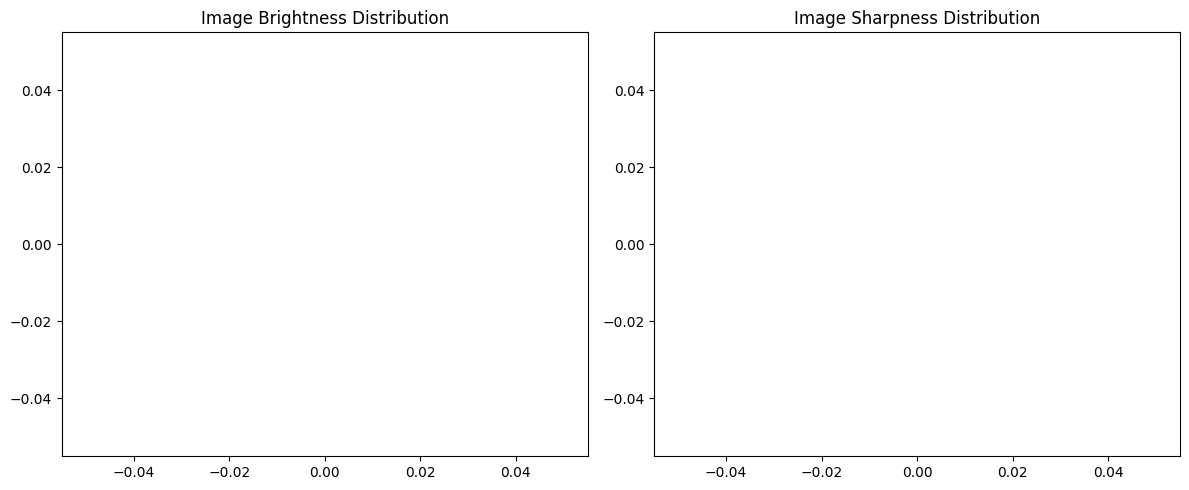

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["Brightness"], kde=True)
plt.title("Image Brightness Distribution")

plt.subplot(1, 2, 2)
sns.histplot(df["Sharpness"], kde=True)
plt.title("Image Sharpness Distribution")

plt.tight_layout()
plt.show()

In [10]:
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):

    class_path = os.path.join(dataset_path, class_name)

    if not os.path.exists(class_path):
        continue

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    if len(images) == 0:
        continue

    image_path = os.path.join(class_path, images[0])

    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

In [11]:
from google.colab import files

uploaded_csv = files.upload()

annotation_path = next(iter(uploaded_csv.keys()))

annotations = pd.read_csv(annotation_path)

print(annotations.head())

Saving traffic_annotation_results.csv to traffic_annotation_results.csv
   Image ID       Category  X Coordinate  Y Coordinate  Width  Height  \
0         1            car           239           258     90      62   
1         1  auto_rickshaw           448           280     72      55   
2         1            bus           346           272    135      55   
3         2  auto_rickshaw           313           272     84      48   
4         2            bus           279           333    137      67   

   Box Area  
0      5580  
1      3960  
2      7425  
3      4032  
4      9179  


In [12]:
print("Available columns:")
print(annotations.columns.tolist())

print("\nFirst 5 rows:")
print(annotations.head())

Available columns:
['Image ID', 'Category', 'X Coordinate', 'Y Coordinate', 'Width', 'Height', 'Box Area']

First 5 rows:
   Image ID       Category  X Coordinate  Y Coordinate  Width  Height  \
0         1            car           239           258     90      62   
1         1  auto_rickshaw           448           280     72      55   
2         1            bus           346           272    135      55   
3         2  auto_rickshaw           313           272     84      48   
4         2            bus           279           333    137      67   

   Box Area  
0      5580  
1      3960  
2      7425  
3      4032  
4      9179  


In [13]:
# Annotation Validation

print("========== ANNOTATION VALIDATION ==========")

# Check missing values
print("\n1. Missing Values:")
print(annotations.isnull().sum())

# Check duplicate rows
print("\n2. Duplicate Entries:")
print(annotations.duplicated().sum())

# Check whether required columns exist
if 'image_name' in annotations.columns and 'class' in annotations.columns:

    # Check invalid class names
    invalid_classes = annotations[
        ~annotations['class'].isin(classes)
    ]

    print("\n3. Invalid Class Names:")
    print(invalid_classes)

    # Check duplicate image names
    duplicate_images = annotations[
        annotations.duplicated(
            subset=['image_name'],
            keep=False
        )
    ]

    print("\n4. Duplicate Image Names:")
    print(duplicate_images)

else:
    print("\nRequired columns not found!")
    print("Available columns:", annotations.columns.tolist())

========== ANNOTATION VALIDATION ==========

1. Missing Values:
Image ID        0
Category        0
X Coordinate    0
Y Coordinate    0
Width           0
Height          0
Box Area        0
dtype: int64

2. Duplicate Entries:
0

Required columns not found!
Available columns: ['Image ID', 'Category', 'X Coordinate', 'Y Coordinate', 'Width', 'Height', 'Box Area']


In [14]:
# FINAL DATASET AUDIT REPORT

print("========== DATASET AUDIT REPORT ==========")

# Total valid images
print("\n1. Total Valid Images:", len(df))

# Class distribution
print("\n2. Class Distribution:")

for name, count in class_counts.items():
    print(name, ":", count)

# Corrupted images
print("\n3. Corrupted Images:", len(corrupted_images))

# Annotation validation
print("\n4. Annotation Validation:")

if 'annotations' in globals():

    print("Missing Values:",
          annotations.isnull().sum().sum())

    print("Duplicate Rows:",
          annotations.duplicated().sum())

    if 'class' in annotations.columns:

        invalid_count = (
            ~annotations['class'].isin(classes)
        ).sum()

        print("Invalid Class Labels:", invalid_count)

    else:
        print("Class column not available")

else:
    print("Annotation file not uploaded")

print("\n========== AUDIT COMPLETED ==========")

========== DATASET AUDIT REPORT ==========

1. Total Valid Images: 0

2. Class Distribution:
Crop_Stress : 0
Diseased : 0
Healthy : 0
Pest_Affected : 0
Weed_Affected : 0

3. Corrupted Images: 0

4. Annotation Validation:
Missing Values: 0
Duplicate Rows: 0
Class column not available

========== AUDIT COMPLETED ==========
